In [4]:
import sys
print(sys.executable)
import os
print(os.getcwd())

d:\miniconda\miniconda\envs\ctlearn\python.exe
d:\TJH课题工作内容\clinicaltransformer\studyplan\notebooks\week01


# Week 1 EDA — Chowell 2021

- Question: 训练集/测试集多大？缺失情况如何？Response 比例多少？各癌种样本量？
     ——训练集1184行，28列；测试集295行28列
     ——无缺失
     ——训练集0.269Response
     ——癌种分布见下图
- Data: data/raw/chowell_train.csv, data/raw/chowell_test.csv
- Method: pandas 描述统计
- Limitation: 单次固定划分，不能代表论文的 10 次划分

In [6]:
# 导入数据+设置工作路径
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent

print("ROOT:", ROOT)

train = pd.read_csv(ROOT / "data/raw/chowell_train.csv")
test = pd.read_csv(ROOT / "data/raw/chowell_test.csv")

print("train:", train.shape)
print("test:", test.shape)

ROOT: d:\TJH课题工作内容\clinicaltransformer\studyplan
train: (1184, 28)
test: (295, 28)


In [7]:
# 看列名和前几行
print(train.columns.tolist())
train.head()

['SAMPLE_ID', 'Cancer_type_grouped_2', 'Cancer_Type2', 'Cancer_Type', 'Chemo_before_IO (1:Yes; 0:No)', 'Age', 'Sex (1:Male; 0:Female)', 'BMI', 'Stage (1:IV; 0:I-III)', 'Stage at IO start', 'NLR', 'Platelets', 'HGB', 'Albumin', 'Drug (1:Combo; 0:PD1/PDL1orCTLA4)', 'Drug_class', 'TMB', 'FCNA', 'HED', 'HLA_LOH', 'MSI (1:Unstable; 0:Stable_Indeterminate)', 'MSI_SCORE', 'Response (1:Responder; 0:Non-responder)', 'OS_Event', 'OS_Months', 'PFS_Event', 'PFS_Months', 'RF16_prob']


,SAMPLE_ID,Cancer_type_grouped_2,Cancer_Type2,Cancer_Type,Chemo_before_IO (1:Yes; 0:No),Age,Sex (1:Male; 0:Female),BMI,Stage (1:IV; 0:I-III),Stage at IO start,...,HED,HLA_LOH,MSI (1:Unstable; 0:Stable_Indeterminate),MSI_SCORE,Response (1:Responder; 0:Non-responder),OS_Event,OS_Months,PFS_Event,PFS_Months,RF16_prob
0,8461,Bladder,2,Others,1,73.845311,0,22.5,1,IV,...,10.340700,0,0,0.16,0,1,9.067762,1,3.121150,0.223172
1,8588,Bladder,2,Others,1,68.876112,1,26.9,1,IV,...,4.968692,0,0,0.16,0,1,7.195072,1,2.694045,0.107879
2,8639,Bladder,2,Others,1,38.696783,1,27.3,1,IV,...,6.850829,0,0,0.26,0,1,12.484600,1,1.215606,0.413048
3,8738,Bladder,2,Others,1,77.240246,1,25.7,1,IV,...,3.812155,1,0,1.10,0,1,0.788501,1,0.788501,0.083979
4,8658,Bladder,2,Others,1,53.514031,1,21.5,1,IV,...,3.913444,0,0,0.68,0,1,5.979466,1,1.248460,0.126372


In [8]:
# 看数据类型
# int64：整数列
# float64：浮点数列（含小数的列）
# object：字符串列，后面输入模型时需要提前编码
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1184 entries, 0 to 1183
Data columns (total 28 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   SAMPLE_ID                                 1184 non-null   int64  
 1   Cancer_type_grouped_2                     1184 non-null   object 
 2   Cancer_Type2                              1184 non-null   int64  
 3   Cancer_Type                               1184 non-null   object 
 4   Chemo_before_IO (1:Yes; 0:No)             1184 non-null   int64  
 5   Age                                       1184 non-null   float64
 6   Sex (1:Male; 0:Female)                    1184 non-null   int64  
 7   BMI                                       1184 non-null   float64
 8   Stage (1:IV; 0:I-III)                     1184 non-null   int64  
 9   Stage at IO start                         1184 non-null   object 
 10  NLR                                 

In [9]:
# 看缺失率
# 对于缺失列先记录，不着急删行
# 本部分的输出结果含义为没有数据缺失列
missing_pct = (train.isna().mean() * 100).sort_values(ascending=False)
missing_pct[missing_pct > 0].round(2)

Series([], dtype: float64)

In [21]:
# 看结局分布
resp = "Response (1:Responder; 0:Non-responder)" #将列名存成变量resp，便于引用
print(train[resp].value_counts(dropna=False)) #dropna=False：不忽略缺失值,将其单独统计
print()
print(train[resp].value_counts(normalize=True).round(3)) #normalize=True：不再返回计数，而是返回占比
# 本部分结果决定了基线模型“瞎猜的水平”，即如果不使用任何特征，直接预测所有样本为non-responder类（0），则准确率为0.731。
print()
ros = "OS_Event"
print(train[ros].value_counts(dropna=False))
print()
print(train[ros].value_counts(normalize=True).round(3)) 
print()
rpfs = "PFS_Event"
print(train[rpfs].value_counts(dropna=False))
print()
print(train[rpfs].value_counts(normalize=True).round(3))

Response (1:Responder; 0:Non-responder)
0    865
1    319
Name: count, dtype: int64

Response (1:Responder; 0:Non-responder)
0    0.731
1    0.269
Name: proportion, dtype: float64

OS_Event
1    701
0    483
Name: count, dtype: int64

OS_Event
1    0.592
0    0.408
Name: proportion, dtype: float64

PFS_Event
1    991
0    193
Name: count, dtype: int64

PFS_Event
1    0.837
0    0.163
Name: proportion, dtype: float64


In [ ]:
# 看癌种分布及各癌种响应率
train["Cancer_type_grouped_2"].value_counts()
# train.groupby("Cancer_type_grouped_2")[resp].agg(["count", "mean"]).sort_values("count", ascending=False)# 看每一癌种的response率,按照样本量排序
train.groupby("Cancer_type_grouped_2")[resp].agg(["count", "mean"]).sort_values("mean", ascending=False) #看每一癌种response率，按照响应率排序

,count,mean
Cancer_type_grouped_2,,
Melanoma,149,0.442953
Renal,73,0.383562
Endometrial,52,0.326923
Esophageal,35,0.314286
Gastric,51,0.294118
NSCLC,430,0.279070
SCLC,40,0.250000
Colorectal,37,0.243243
Head & Neck,55,0.200000


In [12]:
# 关键数值变量描述
num_cols = ["Age", "BMI", "NLR", "Platelets", "HGB", "Albumin", "TMB", "MSI_SCORE"]
train[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1184.0,62.068338,13.270664,13.982204,54.757016,63.952088,70.921971,94.581793
BMI,1184.0,26.845270,5.629754,15.200000,22.900000,26.200000,30.025000,68.500000
NLR,1184.0,6.125794,6.558671,0.300000,2.787500,4.370000,7.000000,88.000000
Platelets,1184.0,270.536318,116.050491,49.000000,196.000000,250.500000,323.000000,977.000000
HGB,1184.0,11.666385,1.856970,6.800000,10.375000,11.700000,13.000000,17.500000
Albumin,1184.0,3.815625,0.455882,2.100000,3.600000,3.900000,4.100000,4.900000
TMB,1184.0,10.330490,18.690064,0.000000,3.000000,5.300000,10.500000,368.600000
MSI_SCORE,1184.0,1.333682,4.235805,0.000000,0.060000,0.285000,1.010000,42.220000


In [13]:
train.shape
print(train.memory_usage(deep=True).sum() / 1024**2, "MB")

0.49977684020996094 MB


保存到: d:\TJH课题工作内容\clinicaltransformer\studyplan\results
saved: d:\TJH课题工作内容\clinicaltransformer\studyplan\results\w01_eda_two_panel.png


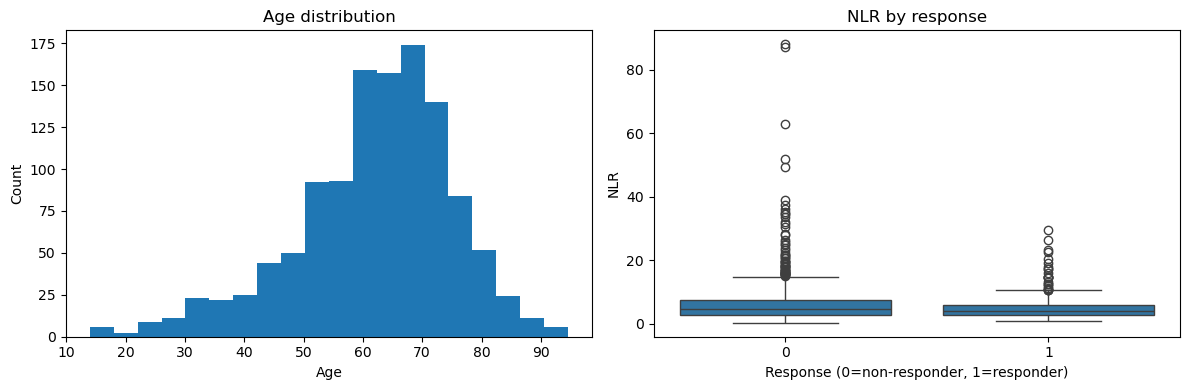

In [19]:
# 绘图
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)
print("保存到:", OUT)

import matplotlib.pyplot as plt
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(train["Age"].dropna(), bins=20)
axes[0].set_title("Age distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Count")

sns.boxplot(data=train, x=resp, y="NLR", ax=axes[1])
axes[1].set_title("NLR by response")
axes[1].set_xlabel("Response (0=non-responder, 1=responder)")

plt.tight_layout()
fig.savefig(OUT / "w01_eda_two_panel.png", dpi=300, bbox_inches="tight")
print("saved:", OUT / "w01_eda_two_panel.png")
plt.show()

In [15]:
# 一个函数
def summarize(df, col):
    s = df[col]
    return {
        "count": s.count(),
        "missing": s.isna().sum(),
        "mean": s.mean(),
        "median": s.median(),
        "min": s.min(),
        "max": s.max(),
    }

summarize(train, "NLR")

{'count': np.int64(1184),
 'missing': np.int64(0),
 'mean': np.float64(6.125793918918919),
 'median': np.float64(4.37),
 'min': np.float64(0.3),
 'max': np.float64(88.0)}